# AIDA 2154 Project Exercise 02 – Image Quality and Preprocessing

**Question:** Are the synthetic onboarding-kit image files complete and consistent, and which preprocessing steps preserve faint icons for later vision methods?

This notebook uses the 500 kit cards, `manifest.csv`, and `icon_instances.csv` from AIDA 2154 Exercise 01. File checks cover all three splits. Preprocessing choices use training cards only, while test cards remain held back for final evaluation.

In [1]:
from pathlib import Path
import hashlib

import cv2
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

EX01_DIR = Path("../01-synthetic-image-specification")
IMAGE_DIR = EX01_DIR / "images"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

ICONS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
CARD_SIZE = (480, 320)  # width, height, from the Exercise 01 generator

manifest = pd.read_csv(EX01_DIR / "manifest.csv")
instances = pd.read_csv(EX01_DIR / "icon_instances.csv")
print(f"Loaded {len(manifest):,} cards and {len(instances):,} icon instances")
print("OpenCV", cv2.__version__)

# Every check is recorded here and saved to outputs/quality_summary.csv at the end
quality_checks = []

def add_check(part, check, passed, detail=""):
    quality_checks.append({"part": part, "check": check, "passed": bool(passed), "detail": detail})

Loaded 500 cards and 1,007 icon instances
OpenCV 4.14.0


## A. File integrity

Each card listed in the manifest should exist, pass Pillow’s file verification, open with OpenCV, and match the expected 480 × 320 RGB PNG format. The checks also look for repeated card IDs or filenames, unlisted files, and icon records without a matching card.

Missing or unreadable files are recorded as failures. Hashes of the pixels decoded by OpenCV identify duplicate images, which are checked against the manifest to confirm that only blank cards are identical.

In [2]:
rows = []
for card in manifest.itertuples():
    path = IMAGE_DIR / card.file_name
    # Every field starts with a "failed" value, so a missing or damaged file can never pass a check
    row = {"card_id": card.card_id, "split": card.split, "exists": path.is_file(), "verified": False,
           "format": None, "mode": None, "width": None, "height": None,
           "opencv_reads": False, "pixel_hash": None, "error": ""}
    if row["exists"]:
        try:
            with Image.open(path) as img:
                img.verify()  # checks the file is a complete, readable image
            row["verified"] = True
            with Image.open(path) as img:
                row.update(format=img.format, mode=img.mode, width=img.width, height=img.height)
            pixels = cv2.imread(str(path))  # OpenCV converts to 3-channel BGR; the Pillow check above confirms the stored format
            row["opencv_reads"] = pixels is not None
            if pixels is not None:
                row["pixel_hash"] = hashlib.md5(pixels.tobytes()).hexdigest()
        except Exception as error:
            row["error"] = str(error)  # kept so a failure can be inspected
    rows.append(row)
files = pd.DataFrame(rows)

listed = set(manifest["file_name"])
extra = sorted(p.name for p in IMAGE_DIR.glob("*") if p.name not in listed)

add_check("A", "One manifest row and file per card",
          len(manifest) == 500 and manifest["card_id"].is_unique and manifest["file_name"].is_unique,
          f"{len(manifest)} rows")
add_check("A", "Every listed file exists", files["exists"].all(), f"{(~files['exists']).sum()} missing")
add_check("A", "No unlisted files in images/", not extra, f"{len(extra)} extra")
add_check("A", "Every file passes Pillow verify", files["verified"].all(), f"{(~files['verified']).sum()} failed")
add_check("A", "Every file is PNG", files["format"].eq("PNG").all(), str(files["format"].value_counts().to_dict()))
add_check("A", "Every file is RGB (3 channels, no transparency)", files["mode"].eq("RGB").all(),
          str(files["mode"].value_counts().to_dict()))
add_check("A", "Every file is 480 x 320", (files["width"].eq(CARD_SIZE[0]) & files["height"].eq(CARD_SIZE[1])).all(), "")
add_check("A", "OpenCV can read every file", files["opencv_reads"].all(), f"{(~files['opencv_reads']).sum()} failed")
add_check("A", "Every icon instance belongs to a listed card", instances["card_id"].isin(manifest["card_id"]).all(), "")

# Matching pixel hashes identify images with identical decoded pixels; unreadable files are left out
hashed = files.dropna(subset=["pixel_hash"])
dupes = hashed[hashed.duplicated("pixel_hash", keep=False)].merge(manifest[["card_id", "n_present"]], on="card_id")
add_check("A", "Identical images are blank cards only", (dupes["n_present"] == 0).all(),
          f"{len(dupes)} cards in {dupes['pixel_hash'].nunique()} identical group(s)")

print("Identical images by split:", dupes.groupby("split").size().reindex(["train", "validation", "test"]).to_dict())
pd.DataFrame(quality_checks)

Identical images by split: {'train': 27, 'validation': 13, 'test': 10}


,part,check,passed,detail
0,A,One manifest row and file per card,True,500 rows
1,A,Every listed file exists,True,0 missing
2,A,No unlisted files in images/,True,0 extra
3,A,Every file passes Pillow verify,True,0 failed
4,A,Every file is PNG,True,{'PNG': 500}
5,A,"Every file is RGB (3 channels, no transparency)",True,{'RGB': 500}
6,A,Every file is 480 x 320,True,
7,A,OpenCV can read every file,True,0 failed
8,A,Every icon instance belongs to a listed card,True,
9,A,Identical images are blank cards only,True,50 cards in 1 identical group(s)


## B. Colour channels and card layout

OpenCV loads images in BGR order, so each card is converted to RGB before comparison with the generator’s colour settings. These checks confirm that the background, header, and border have their expected colours, and that icon rendering boxes stay within the content area.

The background check examines content-area pixels outside the rendering boxes. On blank cards, the entire content area should match the background colour.

The channel summary reports minimum, maximum, and average pixel values by split. Resizing can create edge pixels that differ from the original drawing colours, so later methods should allow colour variation rather than require exact icon-colour matches.

In [3]:
# Layout from the Exercise 01 generator (pixel rows and columns, end values excluded)
BACKGROUND_RGB = (236, 236, 230)
HEADER_RGB = (90, 110, 130)
BORDER_RGB = (120, 120, 120)
BORDER = 2                      # border width in pixels
HEADER_ROWS = slice(BORDER, 37) # header fills rows 0-36; the border covers the outer 2 pixels
CONTENT_ROWS = slice(37, CARD_SIZE[1] - BORDER)
CONTENT_COLS = slice(BORDER, CARD_SIZE[0] - BORDER)

def load_rgb(file_name):
    """Read a card with OpenCV and convert BGR to RGB so colours match the generator settings."""
    return cv2.cvtColor(cv2.imread(str(IMAGE_DIR / file_name)), cv2.COLOR_BGR2RGB)

boxes_by_card = {card_id: group for card_id, group in instances.groupby("card_id")}
channel_rows, layout_rows = [], []
for card in manifest.itertuples():
    rgb = load_rgb(card.file_name)
    for i, channel in enumerate("RGB"):
        values = rgb[:, :, i]
        channel_rows.append({"card_id": card.card_id, "split": card.split, "channel": channel,
                             "min": values.min(), "max": values.max(), "mean": values.mean()})

    # Background = content area with every icon's rendering box blanked out
    outside_icons = np.zeros(rgb.shape[:2], dtype=bool)
    outside_icons[CONTENT_ROWS, CONTENT_COLS] = True
    for box in boxes_by_card.get(card.card_id, pd.DataFrame()).itertuples():
        outside_icons[box.y0:box.y1, box.x0:box.x1] = False

    border = np.ones(rgb.shape[:2], dtype=bool)
    border[BORDER:-BORDER, BORDER:-BORDER] = False
    layout_rows.append({
        "card_id": card.card_id,
        "background_constant": (rgb[outside_icons] == BACKGROUND_RGB).all(),
        "header_constant": (rgb[HEADER_ROWS, CONTENT_COLS] == HEADER_RGB).all(),
        "border_constant": (rgb[border] == BORDER_RGB).all(),
        "content_all_background": (rgb[CONTENT_ROWS, CONTENT_COLS] == BACKGROUND_RGB).all(),
    })
channels = pd.DataFrame(channel_rows)
layout = pd.DataFrame(layout_rows).merge(manifest[["card_id", "n_present"]], on="card_id")

add_check("B", "Background outside icon boxes is exactly (236, 236, 230)", layout["background_constant"].all(),
          f"{(~layout['background_constant']).sum()} cards differ")
add_check("B", "Header is exactly (90, 110, 130)", layout["header_constant"].all(),
          f"{(~layout['header_constant']).sum()} cards differ")
add_check("B", "Border is exactly (120, 120, 120)", layout["border_constant"].all(),
          f"{(~layout['border_constant']).sum()} cards differ")
add_check("B", "Blank-card content areas contain only the background colour",
          layout.loc[layout["n_present"] == 0, "content_all_background"].all(), "")
add_check("B", "All icon boxes have positive size and sit inside the content area",
          (instances["x1"] > instances["x0"]).all() and (instances["y1"] > instances["y0"]).all()
          and (instances["y0"] >= CONTENT_ROWS.start).all() and (instances["y1"] <= CONTENT_ROWS.stop).all()
          and (instances["x0"] >= CONTENT_COLS.start).all() and (instances["x1"] <= CONTENT_COLS.stop).all(), "")

channel_summary = (channels.groupby(["split", "channel"])
                   .agg(min=("min", "min"), max=("max", "max"), mean=("mean", "mean")).round(1)
                   .reindex(pd.MultiIndex.from_product([["train", "validation", "test"], list("RGB")],
                                                       names=["split", "channel"])))
display(pd.DataFrame(quality_checks).query("part == 'B'"))
channel_summary

,part,check,passed,detail
10,B,"Background outside icon boxes is exactly (236,...",True,0 cards differ
11,B,"Header is exactly (90, 110, 130)",True,0 cards differ
12,B,"Border is exactly (120, 120, 120)",True,0 cards differ
13,B,Blank-card content areas contain only the back...,True,
14,B,All icon boxes have positive size and sit insi...,True,


min  max   mean
split      channel                 
train      R         20  255  216.6
           G         50  255  218.4
           B         17  255  215.0
validation R         20  255  216.5
           G         50  255  218.4
           B         17  255  215.2
test       R         20  255  216.7
           G         50  255  218.6
           B         17  255  215.1

## C. Variation across splits

This section compares icon type, size, contrast, position, and the number of icons per card across the three splits. Icon percentages use the drawn icons in each split, while icons-per-card percentages use the cards. Positions are grouped by their centres into top and bottom halves, and left, middle, and right thirds of the content area.

The split was approximately stratified by field department and whether any item was omitted, so other characteristics may differ. These differences are documented without changing the split. Size and contrast combinations are also shown as counts to identify smaller groups that will need caution in later comparisons.

Cards per split: {'train': 300, 'validation': 100, 'test': 100} | icon instances per split: {'train': 599, 'validation': 207, 'test': 201}
Largest gap between splits (percentage points) by factor: {'contrast': 7.4, 'icon': 6.0, 'icons per card': 11.0, 'position': 5.5, 'size': 14.1}


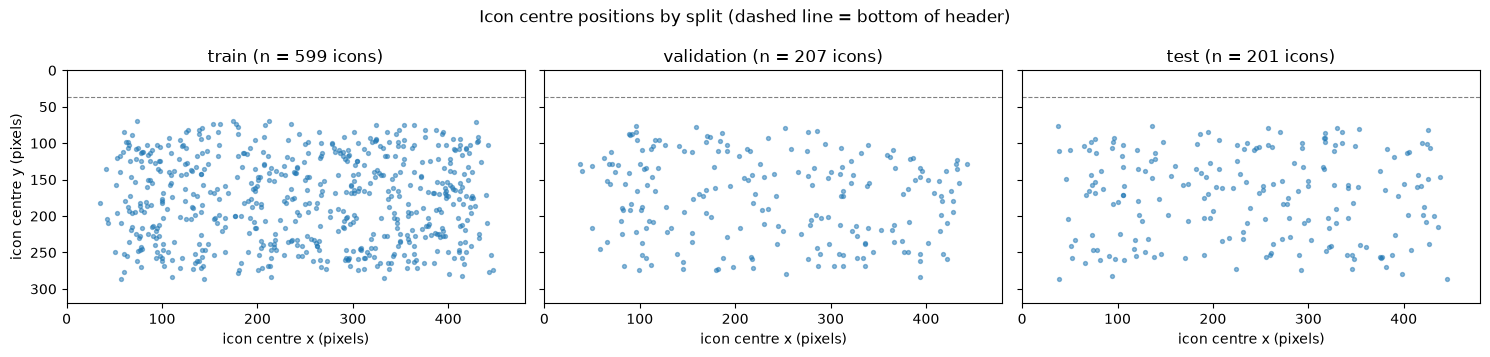

split                         train  validation  test  largest_gap_pts
factor         level                                                  
icon           access_badge    25.2        30.4  24.4              6.0
               safety_vest     23.7        21.7  23.9              2.2
               hard_hat        23.7        23.7  23.9              0.2
               laptop          12.9        13.5  14.4              1.5
               phone           14.5        10.6  13.4              3.9
size           small           32.4        30.4  38.3              7.9
               medium          34.6        46.4  32.3             14.1
               large           33.1        23.2  29.4              9.9
contrast       high            34.6        37.7  30.3              7.4
               medium          36.2        34.8  37.3              2.5
               low             29.2        27.5  32.3              4.8
position       top-left        15.0        18.4  18.9              3.9
               top-middle      18.4        21.3  23.9              5.5
               top-right       17.7        14.5  13.9              3.8
               bottom-left     15.2        14.5  13.9              1.3
               bottom-middle   18.4        16.9  14.4              4.0
               bottom-right    15.4        14.5  14.9              0.9
icons per card 0                9.0        13.0  10.0              4.0
               1               29.0        19.0  30.0             11.0
               2               26.7        28.0  23.0              5.0
               3               24.0        28.0  23.0              5.0
               4               11.3        12.0  14.0              2.7

split            train  validation  test
size   contrast                         
small  high         71          27    27
       medium       72          22    27
       low          51          14    23
medium high         77          36    16
       medium       71          33    23
       low          59          27    26
large  high         59          15    18
       medium       74          17    25
       low          65          16    16

In [4]:
import matplotlib.pyplot as plt

SPLITS = ["train", "validation", "test"]

def share_by_split(frame, column, order):
    """Percentage of rows at each level of `column`, within each split."""
    shares = pd.crosstab(frame[column], frame["split"], normalize="columns").mul(100).round(1)
    return shares.reindex(index=order, columns=SPLITS)

instances["centre_x"] = (instances["x0"] + instances["x1"]) / 2
instances["centre_y"] = (instances["y0"] + instances["y1"]) / 2
# Fixed regions of the content area: top/bottom halves and left/middle/right thirds
mid_y = (CONTENT_ROWS.start + CONTENT_ROWS.stop) / 2
thirds_x = np.linspace(CONTENT_COLS.start, CONTENT_COLS.stop, 4)
instances["position"] = (np.where(instances["centre_y"] < mid_y, "top", "bottom") + "-"
                         + pd.cut(instances["centre_x"], thirds_x, labels=["left", "middle", "right"],
                                  include_lowest=True).astype(str))
manifest["icons_shown"] = manifest["n_present"].astype(str)

variation = pd.concat({
    "icon": share_by_split(instances, "icon", ICONS),
    "size": share_by_split(instances, "scale_level", ["small", "medium", "large"]),
    "contrast": share_by_split(instances, "contrast_level", ["high", "medium", "low"]),
    "position": share_by_split(instances, "position",
                               [f"{r}-{c}" for r in ["top", "bottom"] for c in ["left", "middle", "right"]]),
    "icons per card": share_by_split(manifest, "icons_shown", ["0", "1", "2", "3", "4"]),
}, names=["factor", "level"])
variation["largest_gap_pts"] = variation.max(axis=1).sub(variation.min(axis=1)).round(1)
variation.to_csv(OUTPUT_DIR / "variation_summary.csv")

print("Cards per split:", manifest["split"].value_counts().reindex(SPLITS).to_dict(),
      "| icon instances per split:", instances["split"].value_counts().reindex(SPLITS).to_dict())
print("Largest gap between splits (percentage points) by factor:",
      variation.groupby(level="factor")["largest_gap_pts"].max().to_dict())

# Size x contrast combinations, as counts, so small groups are visible; missing combinations show as 0
combo = pd.crosstab([instances["scale_level"], instances["contrast_level"]], instances["split"]).reindex(
    index=pd.MultiIndex.from_product([["small", "medium", "large"], ["high", "medium", "low"]],
                                     names=["size", "contrast"]), columns=SPLITS)
combo = combo.fillna(0).astype(int)
combo.to_csv(OUTPUT_DIR / "size_contrast_counts.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, split in zip(axes, SPLITS):
    subset = instances[instances["split"] == split]
    ax.scatter(subset["centre_x"], subset["centre_y"], s=8, alpha=0.5)
    ax.set_xlim(0, CARD_SIZE[0])
    ax.set_ylim(CARD_SIZE[1], 0)  # image coordinates: y increases downward
    ax.axhline(CONTENT_ROWS.start, color="grey", lw=0.8, ls="--")
    ax.set_title(f"{split} (n = {len(subset)} icons)")
    ax.set_xlabel("icon centre x (pixels)")
axes[0].set_ylabel("icon centre y (pixels)")
fig.suptitle("Icon centre positions by split (dashed line = bottom of header)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "icon_positions.png", dpi=120)
plt.show()

display(variation)
combo

## D. Human visibility check (training cards only)

This section checks whether a reviewer can identify small and low-contrast icons in a wider training sample. Test cards remain held back.

Each icon contributes three examples from each group: small with low contrast, small with higher contrast, and larger with low contrast. Five blank crops are included as controls. The 50 tiles are randomly ordered and numbered without showing their reference labels. The reviewer records an icon name, `none`, or `unsure` in `visibility_review.csv` before running the scoring cell.

Icons are shown at their original pixel dimensions with a small background margin. Display size and zoom may affect visibility, and isolated crops may be easier to identify than icons on a full card. This is a limited visibility check by one reviewer.

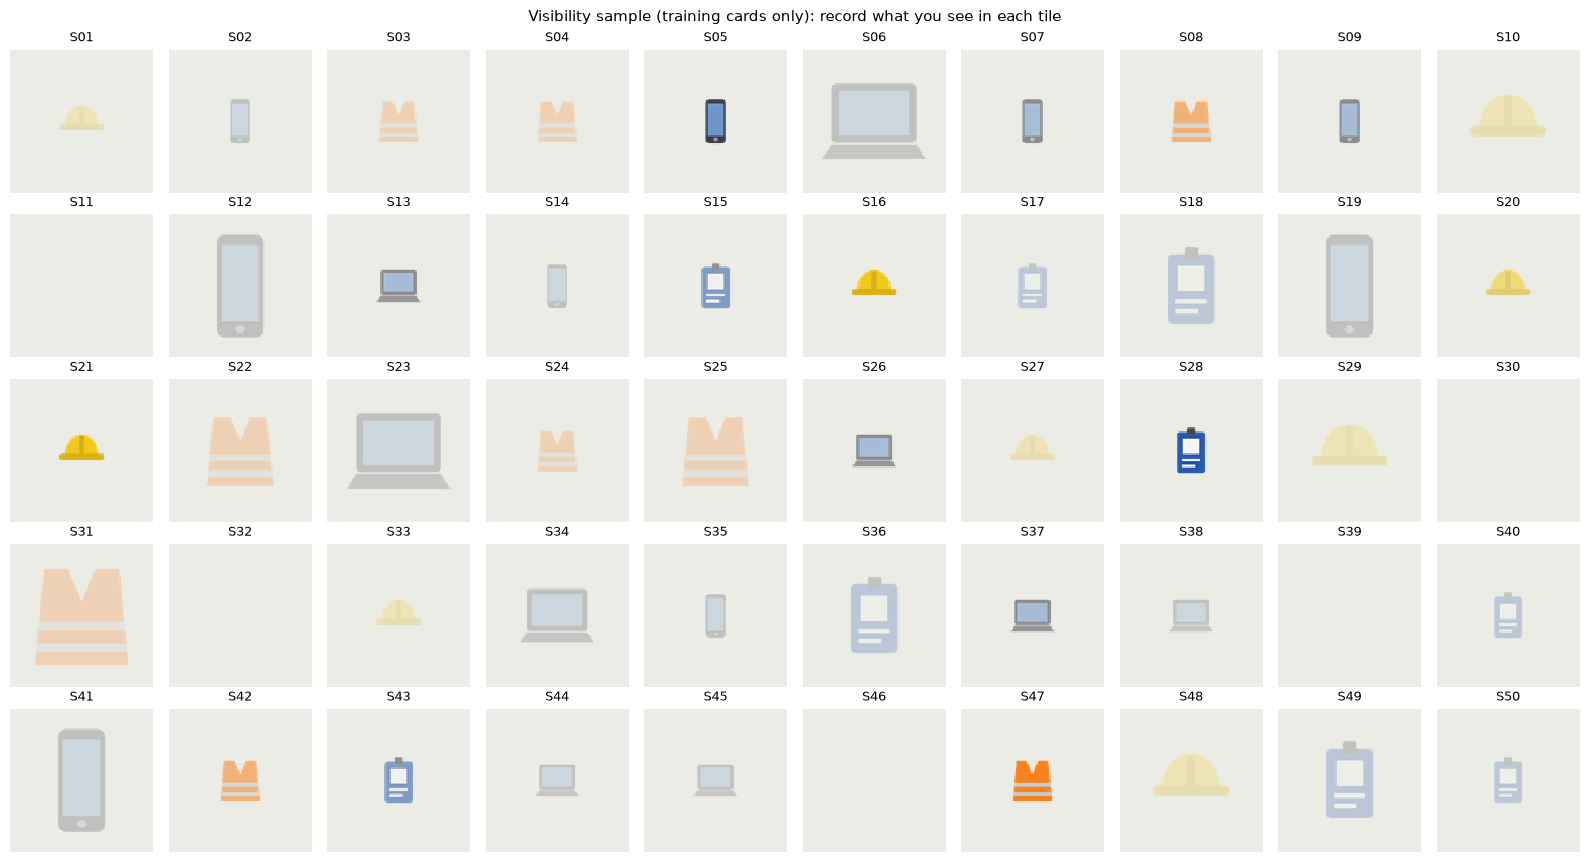

Tiles per group: {'control (no icon)': 5, 'larger, low contrast': 15, 'small + low contrast': 15, 'small, higher contrast': 15}


In [5]:
SEED = 2026
PAD = 8            # background shown around each rendering box
TILE = 110         # every crop is centred on a tile this size, so icons keep their true relative size
PER_GROUP = 3      # icons sampled per icon type and difficulty group
N_CONTROLS = 5     # crops from blank training cards, with no icon
REVIEW_FILE = Path("visibility_review.csv")

file_of = manifest.set_index("card_id")["file_name"]
train_icons = instances[instances["split"] == "train"]
groups = {
    "small + low contrast": (train_icons["scale_level"] == "small") & (train_icons["contrast_level"] == "low"),
    "small, higher contrast": (train_icons["scale_level"] == "small") & (train_icons["contrast_level"] != "low"),
    "larger, low contrast": (train_icons["scale_level"] != "small") & (train_icons["contrast_level"] == "low"),
}
picks = []
for icon in ICONS:
    for group, mask in groups.items():
        chosen = train_icons[mask & (train_icons["icon"] == icon)].sample(PER_GROUP, random_state=SEED)
        picks.append(chosen.assign(group=group))
sample = pd.concat(picks)[["card_id", "icon", "scale_level", "contrast_level", "group", "x0", "y0", "x1", "y1"]]

# Controls: same-size regions from blank training cards, to check that empty space is not reported as an icon
rng = np.random.default_rng(SEED)
blank_cards = manifest[(manifest["split"] == "train") & (manifest["n_present"] == 0)]["card_id"]
controls = []
for card_id in rng.choice(blank_cards, N_CONTROLS, replace=False):
    size = int(rng.choice(sorted(instances["size_px"].unique())))
    x0 = int(rng.integers(CONTENT_COLS.start + PAD, CONTENT_COLS.stop - PAD - size))
    y0 = int(rng.integers(CONTENT_ROWS.start + PAD, CONTENT_ROWS.stop - PAD - size))
    controls.append({"card_id": card_id, "icon": "none", "scale_level": "", "contrast_level": "",
                     "group": "control (no icon)", "x0": x0, "y0": y0, "x1": x0 + size, "y1": y0 + size})
sample = pd.concat([sample, pd.DataFrame(controls)]).sample(frac=1, random_state=SEED).reset_index(drop=True)
sample.insert(0, "sample_id", [f"S{i:02d}" for i in range(1, len(sample) + 1)])

# A short fingerprint of each tile's card and crop position, without its label. It is saved in the
# answer form so that answers cannot be scored against different tiles if the sampling ever changes.
sample["tile_key"] = [hashlib.md5(f"{r.card_id}:{r.x0},{r.y0},{r.x1},{r.y1}".encode()).hexdigest()[:10]
                      for r in sample.itertuples()]

def tile(row):
    """Crop the rendering box plus padding at native size and centre it on a background tile."""
    rgb = load_rgb(file_of[row.card_id])
    crop = rgb[row.y0 - PAD:row.y1 + PAD, row.x0 - PAD:row.x1 + PAD]
    canvas = np.full((TILE, TILE, 3), BACKGROUND_RGB, dtype=np.uint8)
    top, left = (TILE - crop.shape[0]) // 2, (TILE - crop.shape[1]) // 2
    canvas[top:top + crop.shape[0], left:left + crop.shape[1]] = crop
    return canvas

cols = 10
rows_n = int(np.ceil(len(sample) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 1.6, rows_n * 1.75))
for ax, row in zip(axes.flat, sample.itertuples()):
    ax.imshow(tile(row), interpolation="nearest")
    ax.set_title(row.sample_id, fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Visibility sample (training cards only): record what you see in each tile", fontsize=11)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "visibility_sample.png", dpi=120)
plt.show()

# The answer form is created once and never overwritten, so recorded answers survive reruns
if not REVIEW_FILE.exists():
    sample[["sample_id", "tile_key"]].assign(what_you_see="", notes="").to_csv(REVIEW_FILE, index=False)
    print(f"Created {REVIEW_FILE} for recording answers")
print("Tiles per group:", sample.groupby("group").size().to_dict())

### Visibility results

Once all 50 answers are recorded, they are compared with the generator’s presence labels. Results are reported as correct, unsure, or incorrect, with uncertainty kept separate. These results describe this reviewer’s identification of the sampled tiles, not the performance of a vision method.

In [6]:
ANSWERS = set(ICONS) | {"none", "unsure"}
review = pd.read_csv(REVIEW_FILE, keep_default_na=False, dtype=str)

# Stop if rows were deleted or duplicated, or if the tiles no longer match the ones that were reviewed
expected_tiles = dict(zip(sample["sample_id"], sample["tile_key"]))
if not review["sample_id"].is_unique or set(review["sample_id"]) != set(expected_tiles):
    raise ValueError("The review file must contain each current sample_id exactly once.")
if dict(zip(review["sample_id"], review["tile_key"])) != expected_tiles:
    raise ValueError("The tiles have changed since the review form was created. "
                     "Rename the old review file and complete a new review; do not score the old answers.")

review["what_you_see"] = review["what_you_see"].str.strip().str.lower()
answered = review["what_you_see"] != ""
invalid = review.loc[answered & ~review["what_you_see"].isin(ANSWERS), "sample_id"].tolist()

if invalid:
    print("Fix these answers (allowed: " + ", ".join(sorted(ANSWERS)) + "):", invalid)
elif not answered.all():
    print(f"{answered.sum()} of {len(review)} tiles answered; fill in the rest of {REVIEW_FILE.name} and rerun this cell.")
else:
    scored = sample.merge(review.drop(columns="tile_key"), on="sample_id", validate="one_to_one")
    scored["result"] = np.select(
        [scored["what_you_see"] == scored["icon"], scored["what_you_see"] == "unsure"],
        ["correct", "unsure"], default="incorrect")
    visibility_summary = (pd.crosstab(scored["group"], scored["result"])
                          .reindex(columns=["correct", "unsure", "incorrect"], fill_value=0))
    visibility_summary["tiles"] = visibility_summary.sum(axis=1)
    visibility_summary.to_csv(OUTPUT_DIR / "visibility_summary.csv")
    scored.to_csv(OUTPUT_DIR / "visibility_results.csv", index=False)
    missed = scored.loc[scored["result"] != "correct",
                        ["sample_id", "card_id", "icon", "scale_level", "contrast_level", "what_you_see", "notes"]]
    if missed.empty:
        print(f"All {len(scored)} tiles were identified correctly.")
    else:
        print("Tiles not identified correctly:")
        display(missed)
    display(visibility_summary)

All 50 tiles were identified correctly.


result,correct,unsure,incorrect,tiles
group,,,,
control (no icon),5,0,0,5
"larger, low contrast",15,0,0,15
small + low contrast,15,0,0,15
"small, higher contrast",15,0,0,15


## E. Icon signal: grayscale compared with colour difference

This section compares how training icons differ from the card background using two measures:

- **Grayscale difference:** the absolute difference between a pixel’s grayscale value and the background’s grayscale value.
- **Colour difference:** the Euclidean distance between a pixel’s RGB values and the background colour, (236, 236, 230).

The calculation includes pixels inside each rendering box that differ from the background. Each icon’s average difference is calculated first, then the table reports the median for each icon type and contrast level. Counts show how many icon instances contribute to each result.

The measures use different scales, so their raw values are not directly comparable. Percentages relative to the strongest icon at each contrast level show how signal varies between icon types within each representation. The table also reports the percentage of icon pixels that become equal to the background in grayscale.

These measurements describe pixel differences, not human visibility or detection accuracy. Colour difference shows separation from the background but does not identify the icon. Only training cards are used because the results inform the preprocessing comparison.

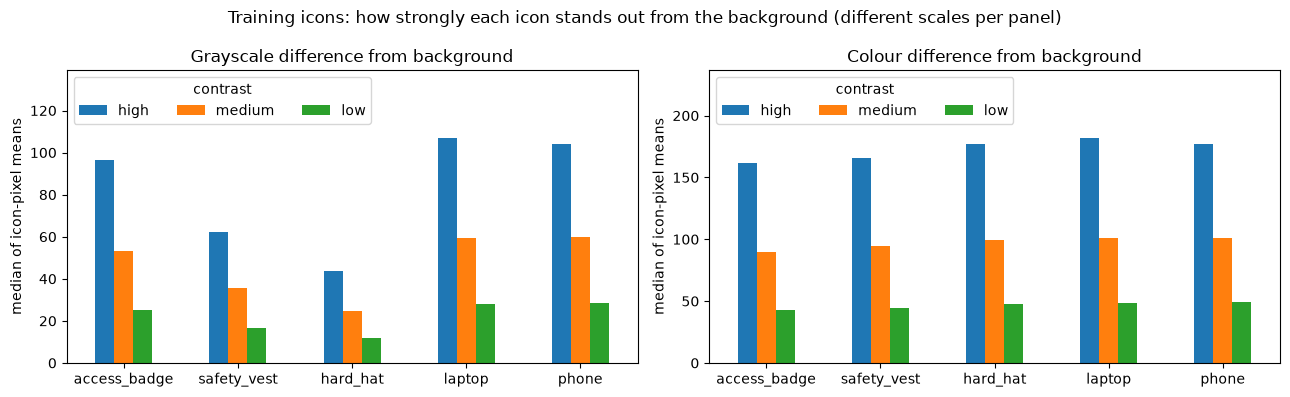

icons  gray_diff  colour_diff  \
icon         contrast_level                                  
access_badge high               50       96.4        161.9   
             medium             55       53.2         89.5   
             low                46       25.3         42.7   
safety_vest  high               51       62.2        165.9   
             medium             48       35.8         94.6   
             low                43       16.8         44.6   
hard_hat     high               52       43.7        177.0   
             medium             52       24.6         99.8   
             low                38       11.7         47.9   
laptop       high               24      107.0        182.0   
             medium             27       59.5        101.1   
             low                26       28.0         48.1   
phone        high               30      104.1        177.3   
             medium             35       59.7        101.4   
             low                22       28.5         49.1   

                             pct_pixels_matching_background_in_gray  \
icon         contrast_level                                           
access_badge high                                               1.1   
             medium                                             1.2   
             low                                                4.8   
safety_vest  high                                               6.1   
             medium                                             5.1   
             low                                                2.4   
hard_hat     high                                               7.9   
             medium                                             8.9   
             low                                                5.8   
laptop       high                                               0.0   
             medium                                             0.0   
             low                                                0.0   
phone        high                                               0.0   
             medium                                             0.0   
             low                                                0.0   

                             gray_diff_vs_strongest_%  \
icon         contrast_level                             
access_badge high                                90.1   
             medium                              89.1   
             low                                 88.7   
safety_vest  high                                58.1   
             medium                              59.9   
             low                                 59.1   
hard_hat     high                                40.8   
             medium                              41.3   
             low                                 40.9   
laptop       high                               100.0   
             medium                              99.7   
             low                                 98.1   
phone        high                                97.3   
             medium                             100.0   
             low                                100.0   

                             colour_diff_vs_strongest_%  
icon         contrast_level                              
access_badge high                                  88.9  
             medium                                88.2  
             low                                   86.9  
safety_vest  high                                  91.1  
             medium                                93.2  
             low                                   90.8  
hard_hat     high                                  97.2  
             medium                                98.4  
             low                                   97.5  
laptop       high                                 100.0  
             medium                                99.7  
             low                          

In [7]:
BACKGROUND_GRAY = int(cv2.cvtColor(np.uint8([[BACKGROUND_RGB]]), cv2.COLOR_RGB2GRAY)[0, 0])
CONTRASTS = ["high", "medium", "low"]

def signal_maps(rgb):
    """Two measures of how far each pixel is from the card background."""
    colour_diff = np.linalg.norm(rgb.astype(float) - BACKGROUND_RGB, axis=2)  # straight-line RGB distance
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(float)
    gray_diff = np.abs(gray - BACKGROUND_GRAY)
    return colour_diff, gray_diff

signal_rows = []
for icon_row in instances[instances["split"] == "train"].itertuples():
    rgb = load_rgb(file_of[icon_row.card_id])[icon_row.y0:icon_row.y1, icon_row.x0:icon_row.x1]
    colour_diff, gray_diff = signal_maps(rgb)
    icon_pixels = colour_diff > 0  # pixels in the rendering box that differ from the background at all
    signal_rows.append({
        "icon": icon_row.icon, "contrast_level": icon_row.contrast_level,
        "colour_diff": colour_diff[icon_pixels].mean(),
        "gray_diff": gray_diff[icon_pixels].mean(),
        "pct_pixels_matching_background_in_gray": (gray_diff[icon_pixels] == 0).mean() * 100,
    })
signal = pd.DataFrame(signal_rows)

icon_contrast = (signal.groupby(["icon", "contrast_level"])
                 .agg(icons=("icon", "size"), gray_diff=("gray_diff", "median"),
                      colour_diff=("colour_diff", "median"),
                      pct_pixels_matching_background_in_gray=("pct_pixels_matching_background_in_gray", "median"))
                 .reindex(pd.MultiIndex.from_product([ICONS, CONTRASTS], names=["icon", "contrast_level"])))
# Each icon's signal as a share of the strongest icon at the same contrast level, within each measure
for measure in ["gray_diff", "colour_diff"]:
    strongest = icon_contrast.groupby(level="contrast_level")[measure].transform("max")
    icon_contrast[f"{measure}_vs_strongest_%"] = icon_contrast[measure] / strongest * 100
icon_contrast = icon_contrast.round(1)
icon_contrast.to_csv(OUTPUT_DIR / "icon_contrast.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, measure, title in zip(axes, ["gray_diff", "colour_diff"],
                              ["Grayscale difference from background", "Colour difference from background"]):
    values = icon_contrast[measure].unstack("contrast_level").reindex(index=ICONS, columns=CONTRASTS)
    values.plot.bar(ax=ax, rot=0)
    ax.set_ylim(0, values.to_numpy().max() * 1.3)  # headroom so the legend does not cover bars
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("median of icon-pixel means")
    ax.legend(title="contrast", loc="upper left", ncol=3)
fig.suptitle("Training icons: how strongly each icon stands out from the background (different scales per panel)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "icon_signal.png", dpi=120)
plt.show()

icon_contrast

## F. Preprocessing and before/after examples

Each card is cropped to its content area, removing the header and border, which Part B showed are fixed colours and which resemble the device icons. Three representations of the cropped area are produced for later comparison:

- **Content RGB:** the cropped colour image, unchanged.
- **Grayscale:** OpenCV's standard grayscale conversion.
- **Colour difference:** each pixel's Euclidean RGB distance from the background colour, scaled to 0–255 using the largest possible distance (from the background to black) and kept as decimal values so faint differences are not rounded to zero. Background pixels become 0.

The same fixed steps are applied to every card in every split; nothing is fitted to the data. Cards are not resized because all are 480 × 320, no noise removal is applied because the cards contain no noise, and contrast is not stretched per card because the fixed background allows one scale for every card. Preprocessed images are not saved because they can be recreated quickly.

Part E compares how icon signal varies between the representations. Detection performance will be evaluated in later exercises. These examples use training cards containing a low-contrast hard hat. Grayscale is displayed over 0–255 and colour difference over 0–100 to make faint differences easier to inspect. The different display ranges mean the figure should not be used alone to judge which representation is better.

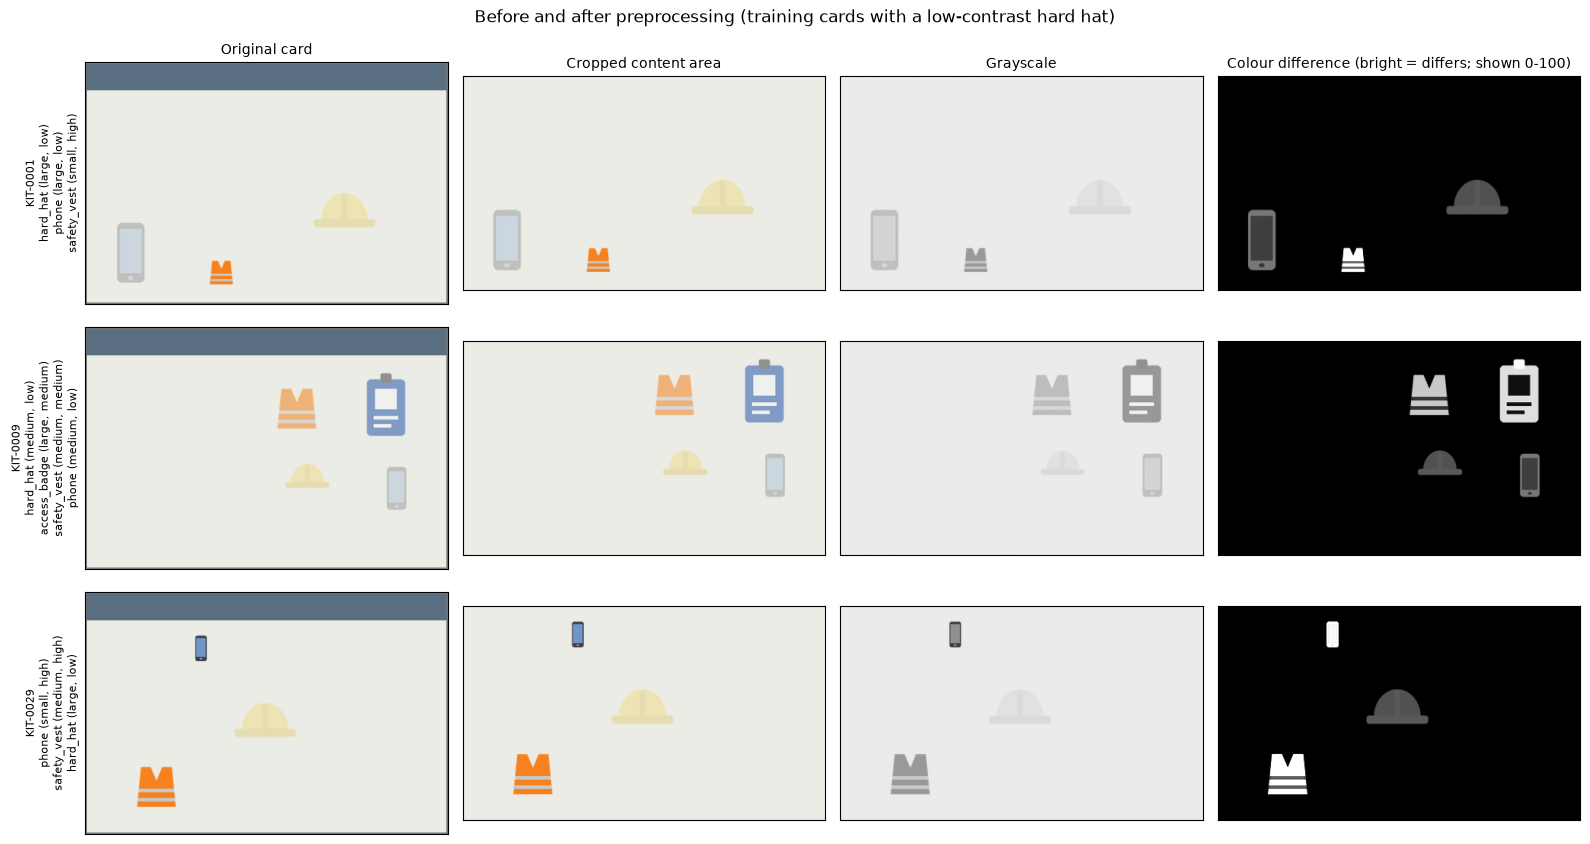

,part,check,passed,detail
15,F,Every card's preprocessed views have the same ...,True,476 x 281 pixels
16,F,Blank cards' colour-difference maps are all zero,True,50 blank cards


In [8]:
# Largest possible colour difference: background to black, used to put colour difference on a fixed 0-255 scale
MAX_COLOUR_DIFF = float(np.linalg.norm(BACKGROUND_RGB))

def preprocess(rgb):
    """Crop to the content area and return the three representations compared in this exercise.

    The same fixed steps are applied to every card in every split; nothing is fitted to the data.
    """
    content = rgb[CONTENT_ROWS, CONTENT_COLS]
    colour_diff, _ = signal_maps(content)
    return {
        "content_rgb": content,
        "gray": cv2.cvtColor(content, cv2.COLOR_RGB2GRAY),
        # Kept as decimals, so faint differences below one grey level are not rounded away to zero
        "colour_diff": np.clip(colour_diff / MAX_COLOUR_DIFF * 255, 0, 255).astype(np.float32),
    }

# Check output dimensions and blank-card colour-difference maps
crop_shape = (CONTENT_ROWS.stop - CONTENT_ROWS.start, CONTENT_COLS.stop - CONTENT_COLS.start)
shapes_ok, blank_maps_zero = [], []
for card in manifest.itertuples():
    views = preprocess(load_rgb(card.file_name))
    shapes_ok.append(all(v.shape[:2] == crop_shape for v in views.values()))
    if card.n_present == 0:
        blank_maps_zero.append((views["colour_diff"] == 0).all())
add_check("F", "Every card's preprocessed views have the same content-crop size", all(shapes_ok),
          f"{crop_shape[1]} x {crop_shape[0]} pixels")
add_check("F", "Blank cards' colour-difference maps are all zero", all(blank_maps_zero),
          f"{len(blank_maps_zero)} blank cards")

# Before/after examples: training cards with a low-contrast hard hat, chosen in card order so they are reproducible
low_hat_cards = instances.query("split == 'train' and icon == 'hard_hat' and contrast_level == 'low'")["card_id"]
example_cards = manifest[manifest["card_id"].isin(low_hat_cards) & (manifest["n_present"] >= 3)]["card_id"].head(3)
if example_cards.empty:
    raise ValueError("No training card has a low-contrast hard hat and at least three icons; choose other examples.")
DIFF_DISPLAY_MAX = 100  # display range only, so faint differences are visible; display settings do not change the returned arrays
columns = [("original", None, 255), ("content_rgb", None, 255), ("gray", "gray", 255),
           ("colour_diff", "gray", DIFF_DISPLAY_MAX)]
titles = ["Original card", "Cropped content area", "Grayscale",
          f"Colour difference (bright = differs; shown 0-{DIFF_DISPLAY_MAX})"]
fig, axes = plt.subplots(len(example_cards), len(columns), figsize=(16, 2.9 * len(example_cards)), squeeze=False)
for r, card_id in enumerate(example_cards):
    rgb = load_rgb(file_of[card_id])
    views = {"original": rgb, **preprocess(rgb)}
    for c, (name, cmap, vmax) in enumerate(columns):
        ax = axes[r, c]
        ax.imshow(views[name], cmap=cmap, vmin=0, vmax=vmax)
        ax.set_xticks([])
        ax.set_yticks([])
        if r == 0:
            ax.set_title(titles[c], fontsize=10)
    shown = instances[instances["card_id"] == card_id]
    axes[r, 0].set_ylabel(card_id + "\n" + "\n".join(f"{i.icon} ({i.scale_level}, {i.contrast_level})"
                                                     for i in shown.itertuples()), fontsize=8)
fig.suptitle("Before and after preprocessing (training cards with a low-contrast hard hat)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "before_after_examples.png", dpi=110)
plt.show()

pd.DataFrame(quality_checks).query("part == 'F'")

## G. Quality summary

All automated checks from Parts A, B, and F are saved to `outputs/quality_summary.csv`. The human visibility results from Part D are saved separately because they record one reviewer's judgements rather than automated checks.

In [9]:
quality_summary = pd.DataFrame(quality_checks)
quality_summary.to_csv(OUTPUT_DIR / "quality_summary.csv", index=False)
print(f"{quality_summary['passed'].sum()} of {len(quality_summary)} automated checks passed")
quality_summary

17 of 17 automated checks passed


,part,check,passed,detail
0,A,One manifest row and file per card,True,500 rows
1,A,Every listed file exists,True,0 missing
2,A,No unlisted files in images/,True,0 extra
3,A,Every file passes Pillow verify,True,0 failed
4,A,Every file is PNG,True,{'PNG': 500}
5,A,"Every file is RGB (3 channels, no transparency)",True,{'RGB': 500}
6,A,Every file is 480 x 320,True,
7,A,OpenCV can read every file,True,0 failed
8,A,Every icon instance belongs to a listed card,True,
9,A,Identical images are blank cards only,True,50 cards in 1 identical group(s)
